# Partie 3 — Prétraitement & Feature Engineering

**Projet :** prédiction du churn client (groupe de 5)
**Responsable :** Mamadou Diagne (Membre 3)
**Entrée :** `data/raw/telco_customer_churn.csv` (non modifié)
**Sorties :** `notebooks/outputs/` (jeux train/test prêts pour la modélisation, pipeline `preprocessor.joblib`, liste des features)

Étapes :
1. Nettoyage : conversion de `TotalCharges`, harmonisation des variables binaires, contrôles de cohérence
2. Feature engineering : 24 variables construites à partir des constats de l'EDA (partie 2)
3. Découpage train/test stratifié (80/20)
4. Pipeline scikit-learn (imputation, standardisation, encodage) appris **uniquement sur le train**, pour éviter toute fuite de données
5. Contrôles qualité et export

In [1]:
# importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from pathlib import Path
import joblib

In [2]:
# lire le dataset
df = pd.read_csv("../data/raw/telco_customer_churn.csv")

In [3]:
# afficher le dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# info sur les donnees
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# afficher la somme des doublons
df.duplicated().sum()

np.int64(0)

In [6]:
# afficher la somme des donnees nulles dans chaque variable
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Traitement de `TotalCharges`

`TotalCharges` est lu comme du texte : 11 valeurs sont une chaîne `" "`. Elles concernent uniquement les
11 clients avec `tenure = 0`, c'est-à-dire des clients qui viennent de souscrire et **n'ont encore jamais été facturés**.

Choix retenu : **remplacer par 0**, comme le recommandaient les parties 1 et 2. C'est la valeur réelle du montant
déjà payé. Une imputation par la médiane (≈ 1 400 $) donnerait à de nouveaux clients le profil de clients
anciens, ce qui serait incohérent. Supprimer les lignes ferait perdre 11 clients, sans raison.

In [7]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
mask_na = df["TotalCharges"].isna()
print(f"{mask_na.sum()} valeurs non numériques converties en NaN")
display(df.loc[mask_na, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

# Ces clients ont tous tenure = 0 : ils n'ont encore rien payé, leur montant total est donc 0
assert (df.loc[mask_na, "tenure"] == 0).all(), "Valeur manquante pour un client déjà facturé"
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(f"{mask_na.sum()} valeurs remplacées par 0 | NaN restants : {df['TotalCharges'].isna().sum()}")

11 valeurs non numériques converties en NaN


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


11 valeurs remplacées par 0 | NaN restants : 0


### Harmonisation des variables binaires

`SeniorCitizen` est codée 0/1 alors que les autres variables binaires sont en Yes/No : on la passe en Yes/No pour
qu'elle soit encodée comme les autres. La cible `Churn` devient 0 (resté) / 1 (parti).

In [8]:
# Harmonisation des variables binaires & de la cible
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype("int8")

# Nettoyage des noms de colonnes (suppression des espaces éventuels)
df.columns = [c.strip() for c in df.columns]
print("Taux de churn global :", f"{df['Churn'].mean():.2%}")

Taux de churn global : 26.54%


In [9]:
# Contrôles de cohérence numérique
checks = {
    "tenure dans [0, 72]": df["tenure"].between(0, 72).all(),
    "MonthlyCharges > 0": (df["MonthlyCharges"] > 0).all(),
    "TotalCharges >= 0": (df["TotalCharges"] >= 0).all(),
    "TotalCharges ≈ tenure × MonthlyCharges (écart médian < 10 %)":
        (((df["TotalCharges"] - df["tenure"] * df["MonthlyCharges"]).abs()
          / df["TotalCharges"].replace(0, np.nan)).median() < 0.10),
}
for k, v in checks.items():
    print("OK    " if v else "ÉCHEC ", k)
assert all(checks.values()), "Au moins un contrôle de cohérence a échoué"

df = df.drop_duplicates(subset="customerID").reset_index(drop=True)

OK     tenure dans [0, 72]
OK     MonthlyCharges > 0
OK     TotalCharges >= 0
OK     TotalCharges ≈ tenure × MonthlyCharges (écart médian < 10 %)


# Feature Engineering

### Variables créées

Chaque groupe de variables traduit un constat de l'EDA (partie 2) :

| Groupe | Variables | Constat de l'EDA |
|---|---|---|
| Ancienneté | `tenure_group`, `is_new_customer` (≤ 6 mois) | Le churn atteint 47 % la première année puis baisse fortement |
| Services | `n_security_services`, `n_streaming_services`, `n_services_total`, `has_protection_bundle`, `internet_no_protection` | Les clients sans sécurité ni support technique partent beaucoup plus |
| Facturation | `avg_monthly_spend`, `charge_delta`, `charge_ratio`, `charge_per_service`, `log_total_charges` | Les factures élevées sont associées au churn ; `log` réduit l'asymétrie de `TotalCharges` |
| Contrat & paiement | `contract_length_m`, `auto_payment` | Contrat mensuel et chèque électronique sont les modalités les plus à risque |
| Profil & interactions | `has_family`, `fiber_month_to_month`, `new_and_mtm`, `senior_alone` | Les facteurs de risque se cumulent (fibre + contrat mensuel, nouveau client + contrat mensuel) |

Ces variables sont calculées ligne par ligne, sans utiliser d'information des autres clients : on peut donc les
créer avant le découpage train/test sans fuite de données.

In [10]:
# creer les features
def build_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()

    # Ancienneté 
    d["tenure_group"] = pd.cut(
        d["tenure"], bins=[-1, 6, 12, 24, 48, 72],
        labels=["0-6m", "7-12m", "13-24m", "25-48m", "49-72m"]).astype(str)
    d["is_new_customer"] = (d["tenure"] <= 6).astype(int)
    d["tenure_years"] = d["tenure"] / 12

    # Services souscrits
    d["has_internet"] = (d["InternetService"] != "No").astype(int)
    d["has_phone"] = (d["PhoneService"] == "Yes").astype(int)
    security_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
    streaming_cols = ["StreamingTV", "StreamingMovies"]
    d["n_security_services"] = (d[security_cols] == "Yes").sum(axis=1)
    d["n_streaming_services"] = (d[streaming_cols] == "Yes").sum(axis=1)
    d["n_services_total"] = (
        d["n_security_services"] + d["n_streaming_services"]
        + d["has_internet"] + d["has_phone"] + (d["MultipleLines"] == "Yes").astype(int))
    d["has_protection_bundle"] = ((d["OnlineSecurity"] == "Yes") & (d["TechSupport"] == "Yes")).astype(int)
    d["internet_no_protection"] = ((d["has_internet"] == 1) & (d["n_security_services"] == 0)).astype(int)

    # Facturation
    d["avg_monthly_spend"] = np.where(d["tenure"] > 0, d["TotalCharges"] / d["tenure"], d["MonthlyCharges"])
    d["charge_delta"] = d["MonthlyCharges"] - d["avg_monthly_spend"]          # >0 : le client paie plus qu'avant
    d["charge_ratio"] = d["MonthlyCharges"] / d["avg_monthly_spend"].replace(0, np.nan)
    d["charge_per_service"] = d["MonthlyCharges"] / d["n_services_total"].clip(lower=1)
    d["log_total_charges"] = np.log1p(d["TotalCharges"])

    # Contrat & paiement 
    d["is_month_to_month"] = (d["Contract"] == "Month-to-month").astype(int)
    d["contract_length_m"] = d["Contract"].map({"Month-to-month": 1, "One year": 12, "Two year": 24})
    d["auto_payment"] = d["PaymentMethod"].str.contains("automatic").astype(int)
    d["is_electronic_check"] = (d["PaymentMethod"] == "Electronic check").astype(int)

    # Profil & interactions à risque 
    d["has_family"] = ((d["Partner"] == "Yes") | (d["Dependents"] == "Yes")).astype(int)
    d["is_alone"] = ((d["Partner"] == "No") & (d["Dependents"] == "No")).astype(int)
    d["fiber_month_to_month"] = ((d["InternetService"] == "Fiber optic") & (d["is_month_to_month"] == 1)).astype(int)
    d["new_and_mtm"] = ((d["is_new_customer"] == 1) & (d["is_month_to_month"] == 1)).astype(int)
    d["senior_alone"] = ((d["SeniorCitizen"] == "Yes") & (d["is_alone"] == 1)).astype(int)
    return d

df_fe = build_features(df)
new_cols = [c for c in df_fe.columns if c not in df.columns]
print(f"{len(new_cols)} nouvelles variables créées :\n", new_cols)
df_fe[new_cols].describe().T.round(2)

24 nouvelles variables créées :
 ['tenure_group', 'is_new_customer', 'tenure_years', 'has_internet', 'has_phone', 'n_security_services', 'n_streaming_services', 'n_services_total', 'has_protection_bundle', 'internet_no_protection', 'avg_monthly_spend', 'charge_delta', 'charge_ratio', 'charge_per_service', 'log_total_charges', 'is_month_to_month', 'contract_length_m', 'auto_payment', 'is_electronic_check', 'has_family', 'is_alone', 'fiber_month_to_month', 'new_and_mtm', 'senior_alone']


,count,mean,std,min,25%,50%,75%,max
is_new_customer,7043.0,0.21,0.41,0.00,0.00,0.00,0.00,1.00
tenure_years,7043.0,2.70,2.05,0.00,0.75,2.42,4.58,6.00
has_internet,7043.0,0.78,0.41,0.00,1.00,1.00,1.00,1.00
has_phone,7043.0,0.90,0.30,0.00,1.00,1.00,1.00,1.00
n_security_services,7043.0,1.27,1.29,0.00,0.00,1.00,2.00,4.00
n_streaming_services,7043.0,0.77,0.85,0.00,0.00,0.00,2.00,2.00
n_services_total,7043.0,4.15,2.31,1.00,2.00,4.00,6.00,9.00
has_protection_bundle,7043.0,0.16,0.36,0.00,0.00,0.00,0.00,1.00
internet_no_protection,7043.0,0.18,0.38,0.00,0.00,0.00,0.00,1.00
avg_monthly_spend,7043.0,64.76,30.19,13.78,35.94,70.34,90.17,121.40


### Découpage train / test

80 % / 20 %, **stratifié** sur `Churn` pour garder le même taux de churn (26,5 %) dans les deux jeux, et
`random_state=42` pour que tout le groupe obtienne exactement le même découpage.

In [11]:
# Split Train / Test (stratifié)
TARGET = "Churn"
X = df_fe.drop(columns=[TARGET, "customerID"])
y = df_fe[TARGET]
ids = df_fe["customerID"]

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.20, stratify=y, random_state=42)

print(f"Train : {X_train.shape} | churn = {y_train.mean():.2%}")
print(f"Test  : {X_test.shape} | churn = {y_test.mean():.2%}")

Train : (5634, 43) | churn = 26.54%
Test  : (1409, 43) | churn = 26.54%


### Pipeline de prétraitement

- **Variables retirées du pipeline** : `has_phone`, `has_internet`, `is_electronic_check`, `is_month_to_month`,
  `tenure_years` et `is_alone` sont exactement redondantes avec une colonne déjà encodée (corrélation = 1).
  Elles restent dans `telco_clean_features.csv` pour l'analyse.
- **Numériques** : imputation par la médiane (sécurité pour de futures données ; il n'y a plus de NaN ici), puis standardisation.
- **Binaires 0/1** : conservées telles quelles.
- **`tenure_group`** : encodage ordinal, car les tranches sont ordonnées.
- **Nominales** : one-hot ; `drop="if_binary"` garde une seule colonne pour les variables Yes/No.

Le pipeline est appris avec `fit_transform` sur le **train uniquement**, puis appliqué au test avec `transform`.

In [12]:
# Pipeline de preprocessing
# Features créées mais redondantes (corr = 1 avec une colonne déjà encodée) : conservées dans
# le dataset analytique, exclues du pipeline de modélisation.
redundant_features = ["has_phone", "has_internet", "is_electronic_check",
                      "is_month_to_month", "tenure_years", "is_alone"]
X_train = X_train.drop(columns=redundant_features)
X_test = X_test.drop(columns=redundant_features)

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "log_total_charges",
                    "avg_monthly_spend", "charge_delta", "charge_ratio", "charge_per_service",
                    "n_security_services", "n_streaming_services", "n_services_total", "contract_length_m"]

binary_passthrough = ["is_new_customer", "has_protection_bundle",
                      "internet_no_protection", "auto_payment",
                      "has_family", "fiber_month_to_month", "new_and_mtm", "senior_alone"]

ordinal_features = ["tenure_group"]
ordinal_categories = [["0-6m", "7-12m", "13-24m", "25-48m", "49-72m"]]

nominal_features = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
                    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

# Vérifie qu'aucune colonne n'est oubliée / dupliquée
used = numeric_features + binary_passthrough + ordinal_features + nominal_features
assert set(used) == set(X_train.columns), set(X_train.columns) ^ set(used)
assert len(used) == len(set(used))

In [13]:
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
ordinal_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("encoder", OrdinalEncoder(categories=ordinal_categories))])
nominal_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="infrequent_if_exist",
                                                   min_frequency=0.01, sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, numeric_features),
        ("bin", "passthrough", binary_passthrough),
        ("ord", ordinal_pipe, ordinal_features),
        ("nom", nominal_pipe, nominal_features),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
print("Train :", X_train_p.shape, "| Test :", X_test_p.shape)
X_train_p.head()

Train : (5634, 58) | Test : (1409, 58)


,tenure,MonthlyCharges,TotalCharges,log_total_charges,avg_monthly_spend,charge_delta,charge_ratio,charge_per_service,n_security_services,n_streaming_services,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0.102371,-0.521976,-0.262257,0.316915,-0.539986,0.226917,0.195142,-0.922442,-0.215513,1.426246,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,-0.711743,0.337478,-0.503635,0.067683,0.391496,-0.639564,-0.465108,1.455427,-0.215513,-0.912706,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,-0.793155,-0.809013,-0.749883,-0.358545,-0.646102,-1.867855,-2.135732,-1.326275,1.337171,-0.912706,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3867,-0.263980,0.284384,-0.172722,0.389209,0.276552,0.081601,0.015395,-0.931779,0.560829,1.426246,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
3810,-1.281624,-0.676279,-0.989374,-1.995946,-0.674608,0.003149,-0.039073,0.940326,-0.991854,-0.912706,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [14]:
# Contrôles qualité
assert X_train_p.isna().sum().sum() == 0 and X_test_p.isna().sum().sum() == 0, "NaN résiduels"
assert np.isfinite(X_train_p.to_numpy()).all() and np.isfinite(X_test_p.to_numpy()).all(), "Valeurs infinies"
assert list(X_train_p.columns) == list(X_test_p.columns)
assert X_train_p.index.equals(X_train.index)

# Le scaling est bien appris sur le train : moyenne ≈ 0 / écart-type ≈ 1 en train, légers écarts en test
chk = pd.DataFrame({"train_mean": X_train_p[numeric_features].mean(),
                    "train_std": X_train_p[numeric_features].std(),
                    "test_mean": X_test_p[numeric_features].mean(),
                    "test_std": X_test_p[numeric_features].std()}).round(3)
display(chk)
print("Nombre final de features :", X_train_p.shape[1])

,train_mean,train_std,test_mean,test_std
tenure,-0.0,1.0,-0.023,0.998
MonthlyCharges,-0.0,1.0,-0.028,0.992
TotalCharges,0.0,1.0,-0.043,0.972
log_total_charges,-0.0,1.0,-0.036,1.011
avg_monthly_spend,-0.0,1.0,-0.029,0.994
charge_delta,-0.0,1.0,0.013,1.030
charge_ratio,0.0,1.0,0.031,1.018
charge_per_service,0.0,1.0,0.042,1.017
n_security_services,-0.0,1.0,-0.046,0.994
n_streaming_services,-0.0,1.0,-0.048,0.984


Nombre final de features : 58


### Colinéarité : note pour la partie 4

Les 6 colonnes `*_No internet service` (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV,
StreamingMovies) sont **identiques** : elles valent toutes 1 pour les clients sans internet. Ce n'est pas gênant
pour les arbres (Random Forest, Gradient Boosting), mais pour une **régression logistique** il faut en garder
une seule ou utiliser une régularisation (L1/L2), sinon les coefficients ne sont pas interprétables.

In [15]:
# Colinéarité : paires de features très corrélées (|r| > 0.9)
c = X_train_p.corr().abs()
pairs = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
           .loc[lambda s: s > 0.9].sort_values(ascending=False))
display(pairs.head(15).to_frame("|corr|"))

|corr|
InternetService_No                   DeviceProtection_No internet service     1.0
                                     TechSupport_No internet service          1.0
                                     OnlineSecurity_No internet service       1.0
                                     StreamingTV_No internet service          1.0
                                     OnlineBackup_No internet service         1.0
OnlineSecurity_No internet service   StreamingMovies_No internet service      1.0
                                     StreamingTV_No internet service          1.0
                                     TechSupport_No internet service          1.0
                                     DeviceProtection_No internet service     1.0
                                     OnlineBackup_No internet service         1.0
InternetService_No                   StreamingMovies_No internet service      1.0
OnlineBackup_No internet service     StreamingTV_No internet service          1.0
                                     StreamingMovies_No internet service      1.0
DeviceProtection_No internet service TechSupport_No internet service          1.0
                                     StreamingTV_No internet service          1.0

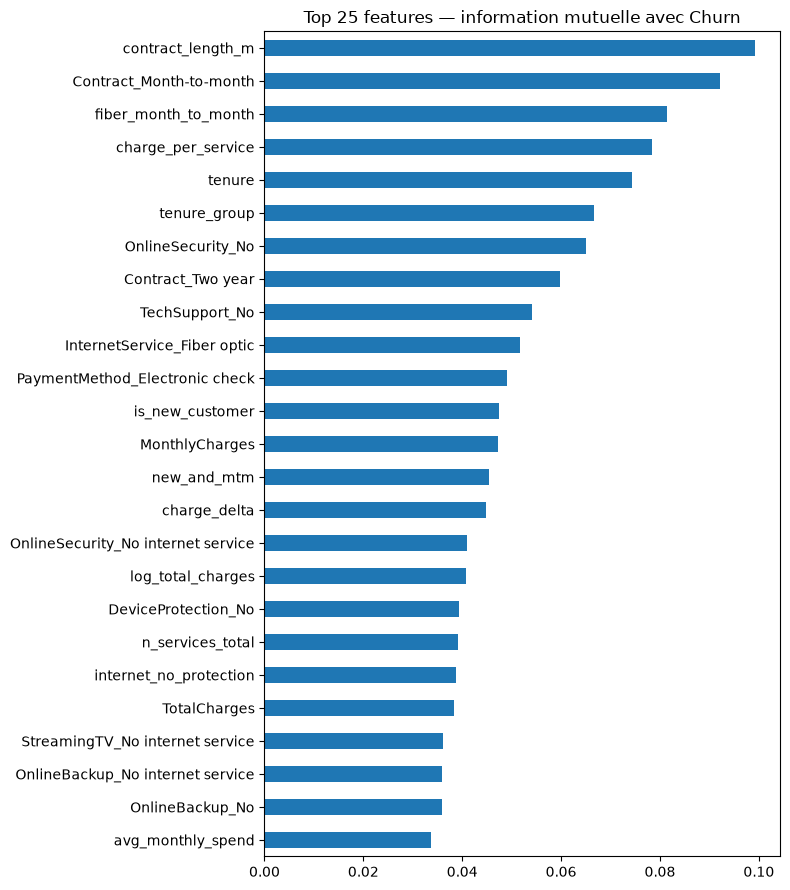

In [16]:
# Importance univariée rapide (information mutuelle) sur le train
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(X_train_p, y_train, random_state=42),
               index=X_train_p.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 9)); mi.head(25).iloc[::-1].plot.barh()
plt.title("Top 25 features — information mutuelle avec Churn"); plt.tight_layout(); plt.show()

### Export

Les fichiers sont écrits dans `notebooks/outputs/`, c'est là que la partie 4 les lit. `preprocessor.joblib`
ne se recharge qu'avec les versions de `requirements.txt` (scikit-learn 1.9.1).

In [17]:
# Export des artefacts
# Jeux prêts pour la modélisation
OUT_DIR = Path("outputs")  # notebooks/outputs/ : dossier lu par la partie 4
OUT_DIR.mkdir(exist_ok=True)
train_out = X_train_p.assign(Churn=y_train.values, customerID=id_train.values)
test_out = X_test_p.assign(Churn=y_test.values, customerID=id_test.values)
train_out.to_csv(OUT_DIR / "train_processed.csv", index=False)
test_out.to_csv(OUT_DIR / "test_processed.csv", index=False)

# Données nettoyées + features (avant encodage/scaling) pour l'analyse
df_fe.to_csv(OUT_DIR / "telco_clean_features.csv", index=False)

# Pipeline fitté (à réutiliser en production / inférence)
joblib.dump(preprocessor, OUT_DIR / "preprocessor.joblib")

# Liste des features finales
pd.Series(X_train_p.columns, name="feature").to_csv(OUT_DIR / "feature_names.csv", index=False)
print("Fichiers exportés :", *[p.name for p in OUT_DIR.iterdir()], sep="\n - ")

Fichiers exportés :
 - feature_names.csv
 - preprocessor.joblib
 - telco_clean_features.csv
 - test_processed.csv
 - train_processed.csv
